In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [ ]:
data = pd.read_csv("heart.csv")

print(data.head())
print(data.shape)

   Age  Resting_Blood_Pressure  Cholesterol  Maximum_Heart_Rate  \
0   63                     145          233                 150   
1   67                     160          286                 108   
2   67                     120          229                 129   
3   37                     130          250                 187   
4   41                     130          204                 172   

   Exercise_Induced_Angina  Heart_Disease  
0                        0              1  
1                        1              0  
2                        1              0  
3                        0              1  
4                        0              1  
(50, 6)


In [ ]:
features = [
    "Age",
    "Resting_Blood_Pressure",
    "Cholesterol",
    "Maximum_Heart_Rate",
    "Exercise_Induced_Angina"
]

X = data[features]
y = data["Heart_Disease"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Age  Resting_Blood_Pressure  Cholesterol  Maximum_Heart_Rate  \
0   63                     145          233                 150   
1   67                     160          286                 108   
2   67                     120          229                 129   
3   37                     130          250                 187   
4   41                     130          204                 172   

   Exercise_Induced_Angina  
0                        0  
1                        1  
2                        1  
3                        0  
4                        0  

Target:
0    1
1    0
2    0
3    1
4    1
Name: Heart_Disease, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40, 5)
Testing data: (10, 5)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

Training data after scaling:
[[ 0.82906369  0.75520108 -0.81067119 -0.62198813  1.29099445]
 [ 1.5296809   2.21101039  1.07433319 -2.10585644  1.29099445]
 [-1.38955746 -0.70060823 -0.02326429  1.35650295 -0.77459667]
 [ 0.24521602 -0.70060823 -0.11870755  1.35650295 -0.77459667]
 [-1.62309652 -1.42851288 -1.76510378 -1.80908278  1.29099445]]


In [ ]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [ ]:
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predicted Classes:")
print(y_pred)

print("\nPredicted Probabilities:")
print(y_prob)

Predicted Classes:
[0 1 1 0 1 1 1 1 1 1]

Predicted Probabilities:
[0.04325188 0.96126964 0.76744155 0.05623902 0.82969541 0.82948777
 0.72413214 0.97493853 0.51521163 0.97643439]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("Model Performance")
print("-----------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Model Performance
-----------------
Accuracy : 0.8
Precision: 0.75
Recall   : 1.0
F1-Score : 0.8571
ROC-AUC  : 0.9583


Confusion Matrix:
[[2 2]
 [0 6]]


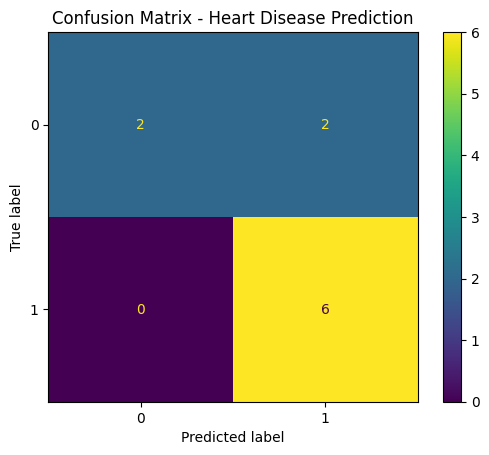

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title("Confusion Matrix - Heart Disease Prediction")
plt.show()

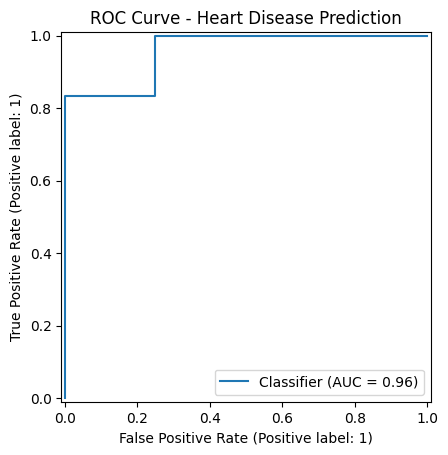

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("ROC Curve - Heart Disease Prediction")
plt.show()

In [ ]:
new_patient = pd.DataFrame([{
    "Age": 55,
    "Resting_Blood_Pressure": 140,
    "Cholesterol": 240,
    "Maximum_Heart_Rate": 150,
    "Exercise_Induced_Angina": 1
}])

new_patient_scaled = scaler.transform(new_patient)

prediction = model.predict(new_patient_scaled)[0]

probability = model.predict_proba(
    new_patient_scaled
)[0, 1]

print("New Patient Prediction")
print("----------------------")

print(
    "Probability of Heart Disease:",
    round(probability, 4)
)

if prediction == 1:
    print("Prediction: Heart Disease Present")
else:
    print("Prediction: No Heart Disease")

New Patient Prediction
----------------------
Probability of Heart Disease: 0.1797
Prediction: No Heart Disease


In [ ]:
np.random.seed(42)

numeric_features = [
    "Age",
    "Resting_Blood_Pressure",
    "Cholesterol",
    "Maximum_Heart_Rate"
]

synthetic_data = data.sample(
    n=150,
    replace=True,
    random_state=42
).copy()

for feature in numeric_features:
    noise = np.random.normal(
        0,
        data[feature].std() * 0.05,
        150
    )

    synthetic_data[feature] = (
        synthetic_data[feature] + noise
    )

synthetic_data["Age"] = synthetic_data["Age"].clip(18, 100)
synthetic_data["Resting_Blood_Pressure"] = synthetic_data[
    "Resting_Blood_Pressure"
].clip(70, 220)

synthetic_data["Cholesterol"] = synthetic_data[
    "Cholesterol"
].clip(100, 500)

synthetic_data["Maximum_Heart_Rate"] = synthetic_data[
    "Maximum_Heart_Rate"
].clip(50, 220)

synthetic_data["Exercise_Induced_Angina"] = (
    synthetic_data["Exercise_Induced_Angina"]
    .round()
    .clip(0, 1)
    .astype(int)
)

print("Synthetic data shape:", synthetic_data.shape)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

data = pd.read_csv("heart.csv")

print("Original dataset shape:", data.shape)

Original dataset shape: (50, 6)


In [ ]:
np.random.seed(42)

numeric_features = [
    "Age",
    "Resting_Blood_Pressure",
    "Cholesterol",
    "Maximum_Heart_Rate"
]

synthetic_data = data.sample(
    n=150,
    replace=True,
    random_state=42
).copy()

for feature in numeric_features:
    noise = np.random.normal(
        0,
        data[feature].std() * 0.05,
        150
    )

    synthetic_data[feature] = (
        synthetic_data[feature] + noise
    )

synthetic_data["Age"] = synthetic_data["Age"].clip(18, 100)
synthetic_data["Resting_Blood_Pressure"] = synthetic_data[
    "Resting_Blood_Pressure"
].clip(70, 220)

synthetic_data["Cholesterol"] = synthetic_data[
    "Cholesterol"
].clip(100, 500)

synthetic_data["Maximum_Heart_Rate"] = synthetic_data[
    "Maximum_Heart_Rate"
].clip(50, 220)

synthetic_data["Exercise_Induced_Angina"] = (
    synthetic_data["Exercise_Induced_Angina"]
    .round()
    .clip(0, 1)
    .astype(int)
)

print("Synthetic data shape:", synthetic_data.shape)

Synthetic data shape: (150, 6)


In [ ]:
expanded_data = pd.concat(
    [data, synthetic_data],
    ignore_index=True
)

print("Original dataset:", len(data))
print("New synthetic data:", len(synthetic_data))
print("Expanded dataset:", len(expanded_data))

print("\nExpanded dataset:")
print(expanded_data.head())

Original dataset: 50
New synthetic data: 150
Expanded dataset: 200

Expanded dataset:
    Age  Resting_Blood_Pressure  Cholesterol  Maximum_Heart_Rate  \
0  63.0                   145.0        233.0               150.0   
1  67.0                   160.0        286.0               108.0   
2  67.0                   120.0        229.0               129.0   
3  37.0                   130.0        250.0               187.0   
4  41.0                   130.0        204.0               172.0   

   Exercise_Induced_Angina  Heart_Disease  
0                        0              1  
1                        1              0  
2                        1              0  
3                        0              1  
4                        0              1  


In [ ]:
print(expanded_data.shape)

print("\nDataset information:")
print(expanded_data.info())

print("\nFirst 10 rows:")
print(expanded_data.head(10))

(200, 6)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      200 non-null    float64
 1   Resting_Blood_Pressure   200 non-null    float64
 2   Cholesterol              200 non-null    float64
 3   Maximum_Heart_Rate       200 non-null    float64
 4   Exercise_Induced_Angina  200 non-null    int64  
 5   Heart_Disease            200 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 9.5 KB
None

First 10 rows:
    Age  Resting_Blood_Pressure  Cholesterol  Maximum_Heart_Rate  \
0  63.0                   145.0        233.0               150.0   
1  67.0                   160.0        286.0               108.0   
2  67.0                   120.0        229.0               129.0   
3  37.0                   130.0        250.0               187.0   
4  41.0               

In [ ]:
features = [
    "Age",
    "Resting_Blood_Pressure",
    "Cholesterol",
    "Maximum_Heart_Rate",
    "Exercise_Induced_Angina"
]

X = expanded_data[features]

y = expanded_data["Heart_Disease"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 5)
y shape: (200,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 5)
Testing data: (40, 5)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Data standardized successfully.")

Data standardized successfully.


In [ ]:
model = LogisticRegression(
    random_state=42
)

model.fit(
    X_train_scaled,
    y_train
)


LogisticRegression(random_state=42)

In [ ]:
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(
    X_test_scaled
)[:, 1]

In [ ]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("Model Performance")
print("-----------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Model Performance
-----------------
Accuracy : 0.85
Precision: 0.7931
Recall   : 1.0
F1-Score : 0.8846
ROC-AUC  : 0.8261


Confusion Matrix:
[[11  6]
 [ 0 23]]


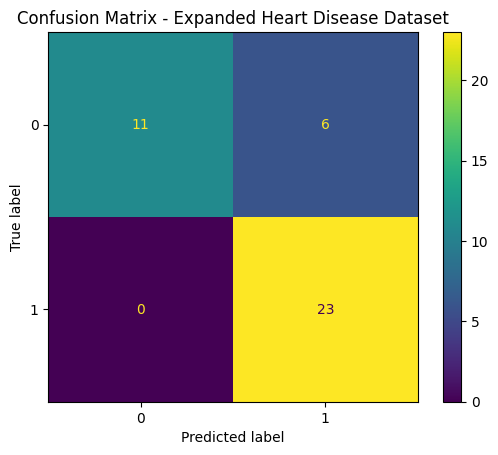

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title(
    "Confusion Matrix - Expanded Heart Disease Dataset"
)

plt.show()

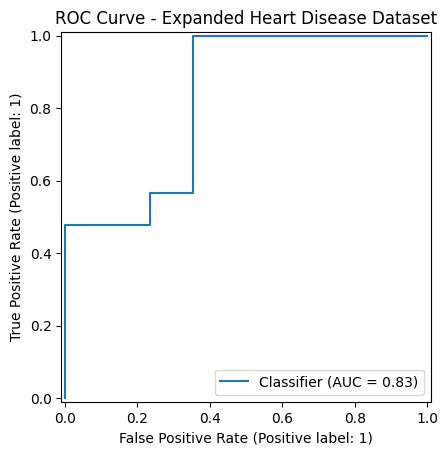

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(
    "ROC Curve - Expanded Heart Disease Dataset"
)

plt.show()

In [ ]:
expanded_data.to_csv(
    "heart_disease_450.csv",
    index=False
)

